# Estadísticas descriptivas de las tablas del proyecto

Calcula, para las variables numéricas principales de cada tabla, las mismas estadísticas descriptivas que dan en R
`summary()` y `psych::describe()`. Las tablas son:

- **Deforestación**: la grilla de 5 km y los cuatro paneles (alertas de GFW, Hansen, IDEAM y detecciones tempranas
  del IDEAM).
- **Crédito**: FINAGRO y SFC 414.
- **Producción agropecuaria**: EVA e ICA pecuario.

Cada tabla se describe tal como está, fila por fila: en los paneles, una fila es una celda en un periodo; en FINAGRO, un
crédito; en la EVA, un cultivo en un municipio y un periodo, y así. Los valores en pesos van en **millones de pesos
corrientes**, y la tasa de FINAGRO va en porcentaje.

La tabla queda en este notebook y se exporta a:

- `docs/figuras/estadisticas_descriptivas.png` (toda la tabla) y una imagen por grupo
  (`..._deforestacion.png`, `..._credito.png`, `..._agropecuario.png`).
- `docs/tablas/estadisticas_descriptivas.xlsx`, con los valores sin redondear.

## Cómo leer la tabla

| Columna | Qué es |
|---|---|
| n | Número de valores que no faltan. |
| Faltantes | Número de valores vacíos. |
| % ceros | Porcentaje de valores que son exactamente cero. |
| Media, Desv. est. | Promedio y desviación estándar (con *n* − 1, como `sd()` en R). |
| Mín., Máx. | Valores mínimo y máximo. |
| Q1, Mediana, Q3 | Cuartiles: el valor que deja por debajo el 25 %, el 50 % y el 75 % de los datos. Se calculan con el método 7, el que usan `summary()` y `quantile()` en R. |
| Asimetría | 0 si la distribución es simétrica; positiva si tiene una cola larga hacia los valores altos. |
| Curtosis | Curtosis en exceso: 0 para una distribución normal; positiva si tiene colas más pesadas que la normal. |

La asimetría y la curtosis se calculan con las mismas fórmulas que `psych::describe()` (su opción por defecto,
`type = 3`). La última sección lo comprueba con R, si R está instalado.

In [1]:
import os
import shutil
import subprocess
import sys
import tempfile
import warnings
from glob import glob
from pathlib import Path

# El notebook vive en notebooks/; las rutas se resuelven desde la raiz del repositorio
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

from pipeline.config_local import DIR_DATOS, DIR_PANEL

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"]})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 250)

DIR_FIGURAS = RAIZ / "docs" / "figuras"
DIR_TABLAS = RAIZ / "docs" / "tablas"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_TABLAS.mkdir(parents=True, exist_ok=True)

ESTADISTICAS = ["n", "Faltantes", "% ceros", "Media", "Desv. est.", "Mín.", "Q1", "Mediana", "Q3", "Máx.",
                "Asimetría", "Curtosis"]


def describir(x):
    # Estadisticas de una variable, como summary() y psych::describe() de R
    x = pd.Series(x, dtype="float64")
    v = x.dropna().to_numpy()
    n = v.size
    d = v - v.mean()
    m2, m3, m4 = (d ** 2).mean(), (d ** 3).mean(), (d ** 4).mean()
    # Asimetria y curtosis en exceso con la correccion de psych::describe (type = 3)
    asimetria = m3 / m2 ** 1.5 * (1 - 1 / n) ** 1.5 if m2 > 0 else np.nan
    curtosis = m4 / m2 ** 2 * (1 - 1 / n) ** 2 - 3 if m2 > 0 else np.nan
    q1, mediana, q3 = np.percentile(v, [25, 50, 75])   # metodo 7 de R, el de quantile() y summary()
    return dict(zip(ESTADISTICAS, [n, int(x.isna().sum()), 100 * (v == 0).mean(), v.mean(), v.std(ddof=1), v.min(),
                                   q1, mediana, q3, v.max(), asimetria, curtosis]))


def describir_tabla(grupo, fuente, tabla, observacion, datos, variables):
    # variables: lista de (columna, unidad, factor por el que se multiplica la columna)
    filas = []
    for columna, unidad, factor in variables:
        filas.append({"Grupo": grupo, "Fuente": fuente, "Tabla": tabla, "Una fila es": observacion,
                      "Filas de la tabla": len(datos), "Variable": columna, "Unidad": unidad,
                      **describir(datos[columna] * factor)})
    return pd.DataFrame(filas)


def numero(v, entero=False, porcentaje=False):
    # Formato en espanol: punto para los miles y coma para los decimales
    if pd.isna(v):
        return "–"
    if porcentaje:
        texto = "<0.01" if 0 < v < 0.01 else f"{v:.2f}"
    elif entero:
        texto = f"{v:,.0f}"
    else:
        a = abs(v)
        texto = ("0" if a == 0 else f"{v:,.0f}" if a >= 1000 else f"{v:,.2f}" if a >= 1
                 else f"{v:.3f}" if a >= 0.01 else f"{v:.2e}")
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")


def formatear(t):
    # Tabla para leer en el notebook: valores con formato, sin las columnas de contexto
    f = t.set_index(["Fuente", "Variable", "Unidad"])[ESTADISTICAS].copy()
    for c in ESTADISTICAS:
        f[c] = f[c].map(lambda v: numero(v, entero=c in ("n", "Faltantes"), porcentaje=c == "% ceros"))
    return f


leer_panel = lambda nombre, columnas: pd.read_parquet(DIR_PANEL / f"{nombre}.parquet", columns=columnas)
leer_profesor = lambda nombre, columnas: pq.read_table(DIR_DATOS / "profesor" / nombre, columns=columnas).to_pandas()

## 1. Deforestación

La grilla se describe una vez, con una fila por celda: `bosque_base_ha` es igual en los cuatro paneles. De los
paneles se describen las variables medidas; los rezagos y la media móvil del panel de GFW se dejan por fuera porque son
el mismo `area_def_ha` corrido en el tiempo.

In [2]:
hansen = leer_panel("panel_hansen", ["cell_id", "perdida_ha", "bosque_base_ha"])
gfw = leer_panel("panel_deforestacion_colombia", ["area_def_ha", "tasa_def", "def_acum_ha", "bosque_remanente_ha"])
ideam = leer_panel("panel_ideam", ["def_ha", "bosque_ideam_ha", "bosque_ideam_fin_ha", "bosque_estable_ha",
                                   "regeneracion_ha", "no_bosque_ha", "sin_info_ha"])
dtd = leer_panel("panel_dtd", ["n_alertas", "n_alertas_sinap"])

deforestacion = pd.concat([
    describir_tabla("Deforestación", "Grilla de 5 km", "bosque base de Hansen por celda", "celda",
                    hansen.drop_duplicates("cell_id"), [("bosque_base_ha", "ha", 1)]),
    describir_tabla("Deforestación", "GFW Integrated Alerts", "panel_deforestacion_colombia", "celda × mes", gfw,
                    [("area_def_ha", "ha", 1), ("tasa_def", "fracción", 1), ("def_acum_ha", "ha", 1),
                     ("bosque_remanente_ha", "ha", 1)]),
    describir_tabla("Deforestación", "Hansen GFC", "panel_hansen", "celda × año", hansen, [("perdida_ha", "ha", 1)]),
    describir_tabla("Deforestación", "IDEAM, cambio de bosque", "panel_ideam", "celda × periodo", ideam,
                    [(c, "ha", 1) for c in ideam.columns]),
    describir_tabla("Deforestación", "IDEAM, detecciones tempranas", "panel_dtd", "celda × trimestre", dtd,
                    [("n_alertas", "puntos", 1), ("n_alertas_sinap", "puntos", 1)]),
])
del hansen, gfw, ideam, dtd
formatear(deforestacion)

n Faltantes % ceros     Media Desv. est.   Mín.      Q1 Mediana        Q3    Máx. Asimetría Curtosis
Fuente                       Variable            Unidad                                                                                                                
Grilla de 5 km               bosque_base_ha      ha           44.616         0    0,00     1.742     828,05  50,00   1.039   2.098     2.492   2.500    -0,718   -0,992
GFW Integrated Alerts        area_def_ha         ha        3.524.664         0   71,99     0,308       2,56      0       0       0     0,024  531,60     34,42    2.596
                             tasa_def            fracción  3.524.664         0   71,99  1,97e-04   1,70e-03      0       0       0  9,93e-06   0,213     29,89    1.517
                             def_acum_ha         ha        3.524.664         0   35,63     13,66      55,84      0       0   0,308      4,53   1.579      9,53   126,16
                             bosque_remanente_ha ha        3.524.664         0    0,00     1.728     827,25  46,41   1.019   2.068     2.488   2.500    -0,689    -1,03
Hansen GFC                   perdida_ha          ha          267.696         0   51,75      5,43      18,22      0       0       0      3,06  657,38      9,11   134,87
IDEAM, cambio de bosque      def_ha              ha          223.080         0   77,90      2,73      13,82      0       0       0         0  621,62     12,17   220,03
                             bosque_ideam_ha     ha          223.080         0    3,81     1.321      1.020      0  240,88   1.314     2.462   2.500    -0,036    -1,75
                             bosque_ideam_fin_ha ha          223.080         0    3,83     1.319      1.020      0  240,06   1.302     2.461   2.500    -0,031    -1,75
                             bosque_estable_ha   ha          223.080         0    3,83     1.319      1.020      0  240,06   1.302     2.461   2.500    -0,031    -1,75
                             regeneracion_ha     ha          223.080         0   99,85  7,47e-03      0,463      0       0       0         0  144,88    187,02   49.098
                             no_bosque_ha        ha          223.080         0   14,27     1.166      1.022      0   34,06   1.131     2.255   2.500     0,058    -1,75
                             sin_info_ha         ha          223.080         0   97,56      1,19      20,57      0       0       0         0   1.782     33,68    1.605
IDEAM, detecciones tempranas n_alertas           puntos    1.115.400         0   95,14     0,199       1,97      0       0       0         0  262,00     32,06    1.838
                             n_alertas_sinap     puntos      803.088   312.312   99,47     0,024      0,723      0       0       0         0  146,00     75,80    8.636

## 2. Crédito

En FINAGRO cada fila es un crédito; en la SFC 414, un grupo de créditos desembolsados en un municipio, un mes y una
combinación de tipo de persona, sexo, tipo de crédito y garantía.

In [3]:
finagro = leer_profesor("finagro", ["valor_credito", "valor_inversion", "plazo", "periodo_gracia", "tasa_total"])
sfc = leer_profesor("sfc414", ["Montos_desembolsados", "Numero_de_creditos_desembolsados",
                               "Tasa_efectiva_promedio_ponderada_AD"])

credito = pd.concat([
    describir_tabla("Crédito", "FINAGRO", "FINAGRO_Desembolsos_EFECTIVA", "crédito", finagro,
                    [("valor_credito", "M$", 1e-6), ("valor_inversion", "M$", 1e-6), ("plazo", "meses", 1),
                     ("periodo_gracia", "meses", 1), ("tasa_total", "%", 100)]),
    describir_tabla("Crédito", "SFC 414", "SFC414_DASH", "municipio × mes × tipo", sfc,
                    [("Montos_desembolsados", "M$", 1e-6), ("Numero_de_creditos_desembolsados", "créditos", 1),
                     ("Tasa_efectiva_promedio_ponderada_AD", "%", 1)]),
])
del finagro, sfc
formatear(credito)

n Faltantes % ceros   Media Desv. est.      Mín.     Q1 Mediana     Q3       Máx. Asimetría   Curtosis
Fuente  Variable                            Unidad                                                                                                                  
FINAGRO valor_credito                       M$        6.158.859         0   <0,01   51,57      1.056         0   3,60    8,00  15,00    405.351    135,94     29.840
        valor_inversion                     M$        6.158.859         0    1,74   76,17      4.514         0   4,00    9,00  15,79  5.800.000    889,67  1.012.915
        plazo                               meses     6.158.859         0    1,88   46,55      30,84         0  18,00   44,00  72,00     324,00     0,483     -0,352
        periodo_gracia                      meses     6.158.859         0   51,69    5,75      10,18     -7,00      0       0   7,00     179,00      2,31       7,01
        tasa_total                          %         6.152.845     6.014   <0,01   17,34      16,89    -17,08   9,82   12,02  16,03     153,23      2,71       7,35
SFC 414 Montos_desembolsados                M$        2.006.169         0    0,00   1.058     24.017  1,00e-08   6,00   22,20  78,80  3.313.299     54,65      3.818
        Numero_de_creditos_desembolsados    créditos  2.006.169         0    0,00  958,09     31.827      1,00   1,00    4,00  21,00  3.112.910     71,85      5.592
        Tasa_efectiva_promedio_ponderada_AD %         2.005.984       185    2,86   28,19      17,34         0  16,40   23,25  36,80      89,73     0,937      0,185

## 3. Producción agropecuaria

En la EVA cada fila es un cultivo en un municipio y un periodo (año o semestre); en el ICA, un municipio en un año. Del
ICA se describen los totales de las siete especies y las fincas con bovinos.

In [4]:
eva = leer_profesor("eva", ["Sembrada", "Cosechada", "Produccion", "Rendimiento"])
ESPECIES = ["total_bovinos", "total_fincas_con_bovinos", "total_bufalos", "total_porcinos", "total_aves",
            "total_equinos", "total_caprinos", "total_ovinos"]
ica = leer_profesor("ica_pecuario", ESPECIES)

agropecuario = pd.concat([
    describir_tabla("Producción agropecuaria", "EVA", "eva_full_enriquecido", "cultivo × municipio × periodo", eva,
                    [("Sembrada", "ha", 1), ("Cosechada", "ha", 1), ("Produccion", "t", 1),
                     ("Rendimiento", "t/ha", 1)]),
    describir_tabla("Producción agropecuaria", "ICA pecuario", "ICA_pecuario", "municipio × año", ica,
                    [(c, "fincas" if "fincas" in c else "animales", 1) for c in ESPECIES]),
])
del eva, ica
formatear(agropecuario)

n Faltantes % ceros    Media Desv. est. Mín.      Q1 Mediana      Q3        Máx. Asimetría Curtosis
Fuente       Variable                 Unidad                                                                                                             
EVA          Sembrada                 ha        347.141         0    0,86   266,38      1.160    0    8,00   29,00  128,00      60.000     15,56   381,74
             Cosechada                ha        347.141         0    2,83   233,64      1.033    0    6,00   24,00  108,00      61.000     16,00   410,06
             Produccion               t         347.141         0    2,67    2.954     46.757    0   27,00  125,00  606,00   4.776.340     56,44    4.273
             Rendimiento              t/ha      343.708     3.433    1,59     9,80      15,18    0    1,60    5,63   12,00      253,00      4,85    33,12
ICA pecuario total_bovinos            animales    8.976         0    1,52   25.441     50.444    0   4.717  10.170  24.867     982.700      7,68   100,33
             total_fincas_con_bovinos fincas      8.976         0    1,53   558,46     549,24    0  222,00  413,50  732,25       7.116      3,42    22,21
             total_bufalos            animales    8.976         0   40,98   388,30      1.724    0       0    4,00   67,00      34.276      9,86   134,89
             total_porcinos           animales    8.976         0    1,65    7.271     22.679    0  475,00   1.650   5.838     572.986     11,11   185,29
             total_aves               animales    8.976         0    1,91  182.143    683.779    0   1.900  10.000  69.384  14.122.870      9,41   123,21
             total_equinos            animales    8.976         0    2,71    1.335      2.118    0  241,00  613,00   1.650      32.527      5,18    44,38
             total_caprinos           animales    8.976         0   15,94   974,01     15.977    0    7,00   37,00  130,00     504.818     26,46   762,81
             total_ovinos             animales    8.976         0   11,89    1.535     12.142    0   31,00  181,00  680,00     342.968     21,00   506,89

## 4. Tabla completa y exportación

**Cómo leer la imagen.** Cada bloque es una tabla, con su fuente, qué es una fila y cuántas filas tiene. Debajo van sus
variables, una por renglón.

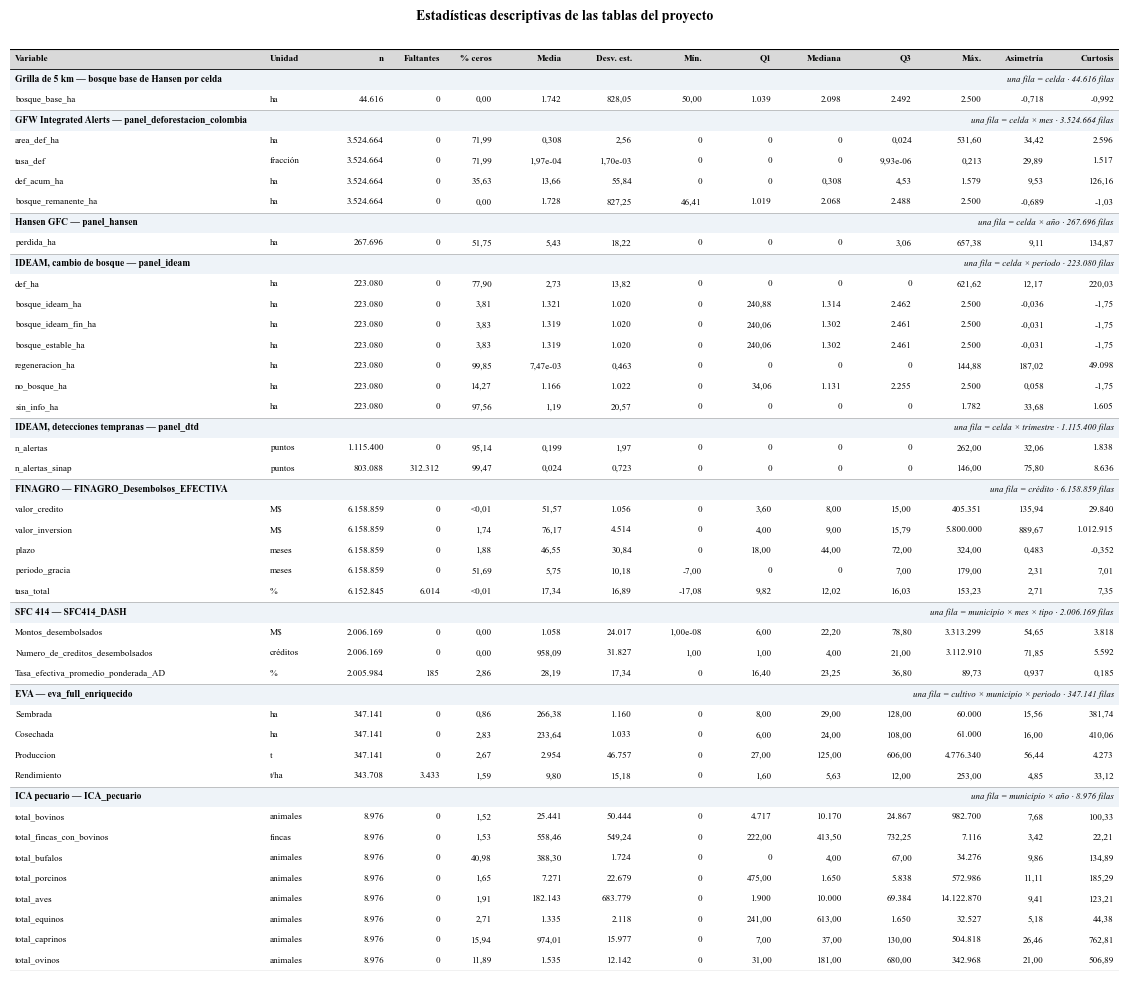

Archivos en docs\figuras y docs\tablas


In [5]:
todas = pd.concat([deforestacion, credito, agropecuario], ignore_index=True)

# Excel con los valores sin redondear
with pd.ExcelWriter(DIR_TABLAS / "estadisticas_descriptivas.xlsx") as excel:
    todas.to_excel(excel, sheet_name="estadisticas", index=False)
    hoja = excel.sheets["estadisticas"]
    for i, ancho in enumerate([22, 28, 30, 26, 14, 36, 10] + [13] * len(ESTADISTICAS)):
        hoja.column_dimensions[chr(65 + i)].width = ancho

ENCABEZADO = ["Variable", "Unidad"] + ESTADISTICAS
ANCHOS = [2.55, 0.62] + [0.62, 0.56, 0.52] + [0.70] * 7 + [0.62, 0.70]
ALTO_FILA = 0.205


def imagen(t, archivo, titulo):
    bloques = list(t.groupby("Tabla", sort=False))
    n_filas = 1 + sum(1 + len(b) for _, b in bloques)
    ancho, alto = sum(ANCHOS), ALTO_FILA * n_filas
    fig = plt.figure(figsize=(ancho + 0.2, alto + 0.55))
    ax = fig.add_axes([0.1 / (ancho + 0.2), 0.05 / (alto + 0.55), ancho / (ancho + 0.2), alto / (alto + 0.55)])
    ax.set(xlim=(0, ancho), ylim=(0, alto))
    ax.set_axis_off()
    bordes = np.r_[0, np.cumsum(ANCHOS)]
    fig.text(0.5, 1 - 0.18 / (alto + 0.55), titulo, ha="center", va="center", fontsize=10, weight="bold")

    def fila(y, textos, negrilla=False, fondo=None):
        if fondo:
            ax.add_patch(plt.Rectangle((0, y - ALTO_FILA), ancho, ALTO_FILA, color=fondo, lw=0))
        for k, texto in enumerate(textos):
            izquierda = k < 2
            x = bordes[k] + 0.05 if izquierda else bordes[k + 1] - 0.05
            ax.text(x, y - ALTO_FILA / 2, texto, ha="left" if izquierda else "right", va="center", fontsize=6.6,
                    weight="bold" if negrilla else "normal")

    y = alto
    fila(y, ENCABEZADO, negrilla=True, fondo="#d9d9d9")
    y -= ALTO_FILA
    for nombre, b in bloques:
        r0 = b.iloc[0]
        ax.add_patch(plt.Rectangle((0, y - ALTO_FILA), ancho, ALTO_FILA, color="#eef3f8", lw=0))
        ax.text(0.05, y - ALTO_FILA / 2, f"{r0.Fuente} — {nombre}", ha="left", va="center", fontsize=6.8,
                weight="bold")
        ax.text(ancho - 0.05, y - ALTO_FILA / 2, f"una fila = {r0['Una fila es']} · {numero(r0['Filas de la tabla'], True)} filas",
                ha="right", va="center", fontsize=6.4, style="italic")
        y -= ALTO_FILA
        for _, r in b.iterrows():
            fila(y, [r.Variable, r.Unidad] + [numero(r[c], entero=c in ("n", "Faltantes"), porcentaje=c == "% ceros")
                                              for c in ESTADISTICAS])
            y -= ALTO_FILA
        ax.plot([0, ancho], [y, y], color="#9a9a9a", lw=0.4)
    ax.plot([0, ancho], [alto, alto], color="black", lw=0.8)
    ax.plot([0, ancho], [alto - ALTO_FILA, alto - ALTO_FILA], color="black", lw=0.6)
    ax.plot([0, ancho], [0, 0], color="black", lw=0.8)
    fig.savefig(DIR_FIGURAS / archivo, dpi=300, facecolor="white")
    return fig


imagen(todas, "estadisticas_descriptivas.png", "Estadísticas descriptivas de las tablas del proyecto")
plt.show()
for t, archivo, titulo in ((deforestacion, "estadisticas_descriptivas_deforestacion.png",
                            "Estadísticas descriptivas: deforestación"),
                           (credito, "estadisticas_descriptivas_credito.png", "Estadísticas descriptivas: crédito"),
                           (agropecuario, "estadisticas_descriptivas_agropecuario.png",
                            "Estadísticas descriptivas: producción agropecuaria")):
    plt.close(imagen(t, archivo, titulo))
print("Archivos en", DIR_FIGURAS.relative_to(RAIZ), "y", DIR_TABLAS.relative_to(RAIZ))

## 5. Comprobación con R

Si R y el paquete `psych` están instalados, se toma una muestra de tres variables, se describe aquí y con
`psych::describe()` en R, y se comparan las cifras. Si R no está, la celda solo lo avisa.

In [6]:
rscript = shutil.which("Rscript") or next(iter(sorted(glob(r"C:\Program Files\R\R-*\bin\Rscript.exe"))), None)
if rscript is None:
    print("R no está instalado: se omite la comprobación.")
else:
    rng = np.random.default_rng(0)
    gfw = leer_panel("panel_deforestacion_colombia", ["area_def_ha"]).area_def_ha
    eva = leer_profesor("eva", ["Cosechada"]).Cosechada
    finagro = leer_profesor("finagro", ["valor_credito"]).valor_credito * 1e-6
    muestra = pd.DataFrame({v.name: rng.choice(v.dropna().to_numpy(), 50_000, replace=False)
                            for v in (gfw, eva, finagro)})
    with tempfile.TemporaryDirectory() as carpeta:
        csv = Path(carpeta) / "muestra.csv"
        muestra.to_csv(csv, index=False)
        orden = (f"d <- read.csv('{csv.as_posix()}'); r <- psych::describe(d); "
                 "write.csv(r[, c('mean', 'sd', 'median', 'skew', 'kurtosis')], stdout())")
        salida = subprocess.run([rscript, "-e", orden], capture_output=True, text=True, check=True).stdout
    from io import StringIO
    en_r = pd.read_csv(StringIO(salida), index_col=0)
    en_r.columns = ["Media", "Desv. est.", "Mediana", "Asimetría", "Curtosis"]
    aqui = pd.DataFrame({c: describir(muestra[c]) for c in muestra}).T[en_r.columns]
    comparacion = pd.concat({"R (psych::describe)": en_r, "este notebook": aqui}, axis=1)
    display(comparacion.round(6))
    print("Diferencia máxima:", np.abs(en_r.to_numpy() - aqui.to_numpy().astype(float)).max())

R (psych::describe)                                               este notebook                                              
                            Media   Desv. est. Mediana  Asimetría      Curtosis         Media   Desv. est. Mediana  Asimetría      Curtosis
area_def_ha              0.306695     2.502996       0  27.426926   1126.444822      0.306695     2.502996     0.0  27.426926   1126.444822
Cosechada              234.309559  1060.799698      24  18.104209    561.055716    234.309559  1060.799698    24.0  18.104209    561.055716
valor_credito           52.590058   990.756512       8  90.342799  10608.177989     52.590058   990.756512     8.0  90.342799  10608.177989

Diferencia máxima: 2.000888343900442e-11
